In [ ]:

# Import required libraries
import pandas as pd
import numpy as np
import zipfile
import os
import glob

# Download dataset
dataset_url = "https://raw.githubusercontent.com/MWiechmann/enron_spam_data/master/enron_spam_data.zip"

!wget -q -O enron_spam_data.zip {dataset_url}

# Extract ZIP file
with zipfile.ZipFile("enron_spam_data.zip", "r") as zip_ref:
    zip_ref.extractall("dataset")

# Find CSV file
csv_files = glob.glob("dataset/**/*.csv", recursive=True)

print("CSV files found:", csv_files)

# Load dataset
df = pd.read_csv(csv_files[0])

print("Dataset downloaded successfully!")


CSV files found: ['dataset/enron_spam_data.csv']
Dataset downloaded successfully!


In [ ]:

# Display first 5 rows
df.head()


,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14
3,3,re : issue,fyi - see note below - already done .\nstella\...,ham,1999-12-14
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,1999-12-14


In [ ]:

# Check number of rows and columns
print("Dataset Shape:", df.shape)

print("Total Emails:", df.shape[0])
print("Total Columns:", df.shape[1])


Dataset Shape: (33716, 5)
Total Emails: 33716
Total Columns: 5


In [ ]:

# Display all column names
print(df.columns.tolist())


['Message ID', 'Subject', 'Message', 'Spam/Ham', 'Date']


In [ ]:

# Display dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33716 entries, 0 to 33715
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Message ID  33716 non-null  int64 
 1   Subject     33427 non-null  object
 2   Message     33345 non-null  object
 3   Spam/Ham    33716 non-null  object
 4   Date        33716 non-null  object
dtypes: int64(1), object(4)
memory usage: 1.3+ MB


In [ ]:

# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())


Missing Values:
Message ID      0
Subject       289
Message       371
Spam/Ham        0
Date            0
dtype: int64


In [ ]:

# Count emails according to their categories

print(df['Spam/Ham'].value_counts())


Spam/Ham
spam    17171
ham     16545
Name: count, dtype: int64


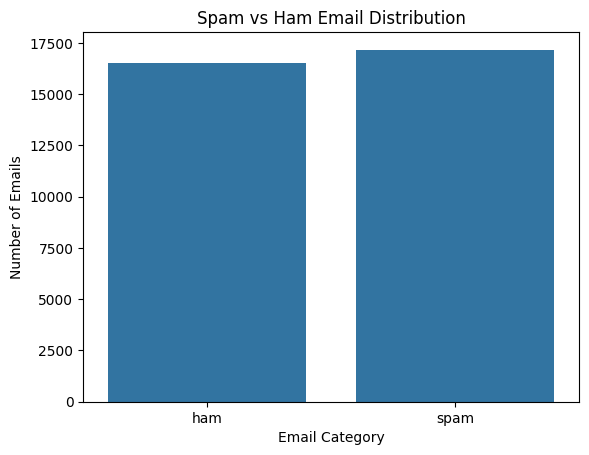

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Visualize spam and ham emails
sns.countplot(data=df, x='Spam/Ham')

plt.title("Spam vs Ham Email Distribution")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")

plt.show()


In [ ]:

# Check missing values in all columns

print("Missing Values in Dataset:")
print(df.isnull().sum())


Missing Values in Dataset:
Message ID      0
Subject       289
Message       371
Spam/Ham        0
Date            0
dtype: int64


In [ ]:

# Handle missing values in text columns

df['Subject'] = df['Subject'].fillna('')
df['Message'] = df['Message'].fillna('')

# Check missing values again
print(df.isnull().sum())


Message ID    0
Subject       0
Message       0
Spam/Ham      0
Date          0
dtype: int64


In [ ]:

# Check duplicate rows

print("Total Duplicate Rows:", df.duplicated().sum())


Total Duplicate Rows: 0


In [ ]:

# Combine email subject and message

df['Email_Text'] = df['Subject'] + ' ' + df['Message']

# Display examples
print(df[['Subject', 'Message', 'Email_Text']].head())


                        Subject  \
0  christmas tree farm pictures   
1      vastar resources , inc .   
2  calpine daily gas nomination   
3                    re : issue   
4     meter 7268 nov allocation   

                                             Message  \
0                                                      
1  gary , production from the high island larger ...   
2             - calpine daily gas nomination 1 . doc   
3  fyi - see note below - already done .\nstella\...   
4  fyi .\n- - - - - - - - - - - - - - - - - - - -...   

                                          Email_Text  
0                      christmas tree farm pictures   
1  vastar resources , inc . gary , production fro...  
2  calpine daily gas nomination - calpine daily g...  
3  re : issue fyi - see note below - already done...  
4  meter 7268 nov allocation fyi .\n- - - - - - -...  


In [ ]:

# Keep only required columns

df = df[['Email_Text', 'Spam/Ham']]

# Display updated dataset
print(df.head())

# Check final shape
print("Final Dataset Shape:", df.shape)


                                          Email_Text Spam/Ham
0                      christmas tree farm pictures       ham
1  vastar resources , inc . gary , production fro...      ham
2  calpine daily gas nomination - calpine daily g...      ham
3  re : issue fyi - see note below - already done...      ham
4  meter 7268 nov allocation fyi .\n- - - - - - -...      ham
Final Dataset Shape: (33716, 2)


**Text Preprocessing**

In [ ]:

# Convert all email text into lowercase

df['Email_Text'] = df['Email_Text'].str.lower()

# Display examples
print(df['Email_Text'].head())


0                        christmas tree farm pictures 
1    vastar resources , inc . gary , production fro...
2    calpine daily gas nomination - calpine daily g...
3    re : issue fyi - see note below - already done...
4    meter 7268 nov allocation fyi .\n- - - - - - -...
Name: Email_Text, dtype: object


/tmp/ipykernel_1424/1560518215.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Email_Text'] = df['Email_Text'].str.lower()


In [ ]:

# Remove extra spaces and new lines

df['Email_Text'] = df['Email_Text'].str.replace(r'\s+', ' ', regex=True).str.strip()

# Display examples
print(df['Email_Text'].head())


0                         christmas tree farm pictures
1    vastar resources , inc . gary , production fro...
2    calpine daily gas nomination - calpine daily g...
3    re : issue fyi - see note below - already done...
4    meter 7268 nov allocation fyi . - - - - - - - ...
Name: Email_Text, dtype: object


/tmp/ipykernel_1424/4097043446.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Email_Text'] = df['Email_Text'].str.replace(r'\s+', ' ', regex=True).str.strip()


In [ ]:

# Remove special characters and numbers

df['Email_Text'] = df['Email_Text'].str.replace(
    r'[^a-zA-Z\s]',
    '',
    regex=True
)

# Remove extra spaces again
df['Email_Text'] = df['Email_Text'].str.replace(
    r'\s+',
    ' ',
    regex=True
).str.strip()

# Display cleaned emails
print(df['Email_Text'].head())


/tmp/ipykernel_1424/455666868.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Email_Text'] = df['Email_Text'].str.replace(


0                         christmas tree farm pictures
1    vastar resources inc gary production from the ...
2    calpine daily gas nomination calpine daily gas...
3    re issue fyi see note below already done stell...
4    meter nov allocation fyi forwarded by lauri a ...
Name: Email_Text, dtype: object


/tmp/ipykernel_1424/455666868.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Email_Text'] = df['Email_Text'].str.replace(


In [ ]:

# Compare cleaned email examples

for i in range(5):
    print(f"Email {i+1}:")
    print(df['Email_Text'].iloc[i])
    print("-" * 50)


Email 1:
christmas tree farm pictures
--------------------------------------------------
Email 2:
vastar resources inc gary production from the high island larger block a commenced on saturday at p m at about gross carlos expects between and gross for tomorrow vastar owns of the gross production george x forwarded by george weissman hou ect on am daren j farmer am to carlos j rodriguez hou ect ect cc george weissman hou ect ect melissa graves hou ect ect subject vastar resources inc carlos please call linda and get everything set up i m going to estimate coming up tomorrow with a increase each following day based on my conversations with bill fischer at bmar d forwarded by daren j farmer hou ect on am enron north america corp from george weissman am to daren j farmer hou ect ect cc gary bryan hou ect ect melissa graves hou ect ect subject vastar resources inc darren the attached appears to be a nomination from vastar resources inc for the high island larger block a previously erroneous

In [ ]:

# Separate input features and target labels

X = df['Email_Text']
y = df['Spam/Ham']

# Check the data
print("Input data:")
print(X.head())

print("\nTarget labels:")
print(y.head())


Input data:
0                         christmas tree farm pictures
1    vastar resources inc gary production from the ...
2    calpine daily gas nomination calpine daily gas...
3    re issue fyi see note below already done stell...
4    meter nov allocation fyi forwarded by lauri a ...
Name: Email_Text, dtype: object

Target labels:
0    ham
1    ham
2    ham
3    ham
4    ham
Name: Spam/Ham, dtype: object


In [ ]:

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))


Training emails: 26972
Testing emails: 6744
Training labels: 26972
Testing labels: 6744


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Learn vocabulary and transform training emails
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing emails using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Display shapes
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)


Training data shape: (26972, 5000)
Testing data shape: (6744, 5000)


In [ ]:

# Get vocabulary words
feature_names = tfidf.get_feature_names_out()

# Display first 20 words
print("First 20 Features:")
print(feature_names[:20])

# Display numerical values of first training email
print("\nTF-IDF Values:")
print(X_train_tfidf[0].toarray())


First 20 Features:
['aa' 'ab' 'abacha' 'abiiity' 'ability' 'able' 'about' 'above' 'abroad'
 'absence' 'absolute' 'absolutely' 'abuse' 'ac' 'academic' 'accept'
 'acceptable' 'acceptance' 'accepted' 'accepting']

TF-IDF Values:
[[0. 0. 0. ... 0. 0. 0.]]


In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Create the Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [ ]:
# Make predictions on test data
y_pred = nb_model.predict(X_test_tfidf)

print("Predictions generated successfully!")

# Display first 10 actual and predicted labels
print("\nActual Labels:")
print(y_test.head(10).values)

print("\nPredicted Labels:")
print(y_pred[:10])

Predictions generated successfully!

Actual Labels:
['spam' 'spam' 'spam' 'ham' 'spam' 'spam' 'ham' 'ham' 'spam' 'ham']

Predicted Labels:
['spam' 'spam' 'spam' 'ham' 'spam' 'spam' 'ham' 'ham' 'spam' 'ham']


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    pos_label='spam'
)

recall = recall_score(
    y_test, y_pred,
    pos_label='spam'
)

f1 = f1_score(
    y_test, y_pred,
    pos_label='spam'
)

# Display results
print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

Model Evaluation Results
------------------------
Accuracy: 0.9847271648873073
Precision: 0.9801152737752161
Recall: 0.9901018922852984
F1-Score: 0.9850832729905865

Detailed Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.98      0.98      3309
        spam       0.98      0.99      0.99      3435

    accuracy                           0.98      6744
   macro avg       0.98      0.98      0.98      6744
weighted avg       0.98      0.98      0.98      6744



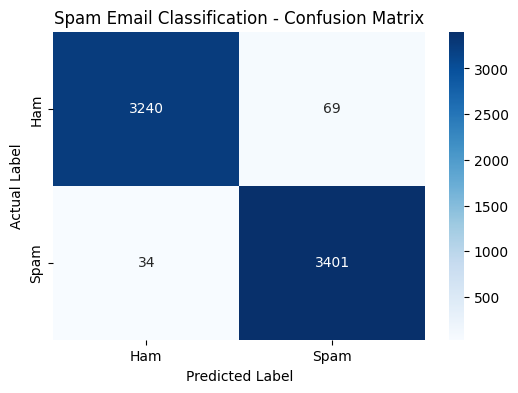

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['ham', 'spam']
)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Spam Email Classification - Confusion Matrix')
plt.show()

In [ ]:
import joblib

# Save trained Naive Bayes model
joblib.dump(nb_model, 'spam_model.pkl')

# Save trained TF-IDF vectorizer
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("Model and TF-IDF Vectorizer saved successfully!")

Model and TF-IDF Vectorizer saved successfully!


In [ ]:
import joblib

# Load the saved model
loaded_model = joblib.load('spam_model.pkl')

# Load the saved TF-IDF vectorizer
loaded_vectorizer = joblib.load('tfidf_vectorizer.pkl')

print("Model and Vectorizer loaded successfully!")

Model and Vectorizer loaded successfully!


In [ ]:
# Create a custom email
new_email = [
    "Congratulations! You have won a free prize. Click here to claim your reward."
]

# Convert email text into TF-IDF features
email_tfidf = loaded_vectorizer.transform(new_email)

# Predict email category
prediction = loaded_model.predict(email_tfidf)

# Display result
if prediction[0] == 'spam':
    print("Result: SPAM EMAIL")
else:
    print("Result: NOT SPAM")

Result: SPAM EMAIL


In [ ]:
import re

def predict_email(email):

    # Step 1: Clean email text
    email = email.lower()
    email = re.sub(r'[^a-zA-Z\s]', '', email)
    email = re.sub(r'\s+', ' ', email).strip()

    # Step 2: Convert text into TF-IDF features
    email_tfidf = loaded_vectorizer.transform([email])

    # Step 3: Predict using trained model
    prediction = loaded_model.predict(email_tfidf)

    # Step 4: Display result
    if prediction[0] == 'spam':
        return "SPAM"
    else:
        return "NOT SPAM"

In [ ]:
test_email = """
Congratulations! You have won a free prize.
Click here now to claim your reward.
"""

result = predict_email(test_email)

print("Email:", test_email)
print("Prediction:", result)

Email: 
Congratulations! You have won a free prize.
Click here now to claim your reward.

Prediction: SPAM


In [ ]:
from google.colab import files

files.download('spam_model.pkl')
files.download('tfidf_vectorizer.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>